# 02 · Datos — descarga de FaceForensics++ (c23) y recorte de caras
Genera `crops/<categoria>/<video_id>/<frame>.png` (299×299) solo para los videos que usan los experimentos:

| Split | Pares oficiales usados | Categorías |
|---|---|---|
| train | 100 de 360 | original + Deepfakes |
| val | 30 de 70 | original + Deepfakes |
| test | 70 de 70 | original + Deepfakes, Face2Face, FaceSwap, NeuralTextures |

Al terminar: **Save Version → Save & Run All**, y luego crear un *Kaggle Dataset* privado a partir del output (`crops/`) para no repetir este paso. Es la decisión D-05 del cuaderno de decisiones.

In [1]:
# Settings de Kaggle: Accelerator = GPU T4 x2 · Internet = On
import os, sys, subprocess
from pathlib import Path
REPO_URL = "https://github.com/Gredith/DeepLearning-G8-TA_Repository.git"
ROOT = Path("/kaggle/working/repo") if Path("/kaggle").exists() else Path.cwd().parents[1]
if Path("/kaggle").exists() and not ROOT.exists():
    subprocess.run(["git", "clone", "-q", REPO_URL, str(ROOT)], check=True)
os.chdir(ROOT); sys.path.insert(0, str(ROOT / "src" / "kaggle_e2"))
print("ROOT =", ROOT)

ROOT = /kaggle/working/repo


In [2]:
!pip install -q --no-deps facenet-pytorch   # --no-deps: evita que reinstale otra versión de torch
import json, pandas as pd, torch
import data as D, preprocess as P
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
FFPP = Path("/kaggle/working/ffpp")      # donde descarga el script oficial
CROPS = Path("/kaggle/working/crops")
N_TRAIN, N_VAL, N_TEST, N_FRAMES, SEED = 100, 30, None, 16, 42

## 1. Descarga (script oficial de FF++)
El script de descarga es el que enviaron los autores con la aprobación del acceso (p. ej. `faceforensics_download_v4.py`). **No se versiona ni se enlaza en el repo** porque los términos de FF++ no permiten redistribuirlo: súbanlo a Kaggle como **Dataset privado** (*Add Input → Upload*). La celda siguiente lo encuentra sola en `/kaggle/input/`.

El script descarga todos los videos de cada tipo. Revisen el espacio con `du -sh` después de cada tipo: Kaggle da ~20 GB en `/kaggle/working`. Si no alcanza, borren los videos de cada método después de recortarlo (celda 3).

In [3]:
def _es_script_ffpp(p):
    n = p.name.lower()
    return n.endswith(".py") and "faceforensics" in n and "download" in n
SCRIPT = next((p for p in Path("/kaggle/input").rglob("*.py") if _es_script_ffpp(p)), None) if Path("/kaggle/input").exists() else None
SCRIPT = SCRIPT or next((p for p in Path("/kaggle/working").glob("*.py") if _es_script_ffpp(p)), None)
assert SCRIPT, "No se encontró el script de FF++: súbanlo como Kaggle Dataset privado (Add Input → Upload)"
print("Script:", SCRIPT)
for kind in ["original", "Deepfakes", "Face2Face", "FaceSwap", "NeuralTextures"]:
    # `echo |` responde a la confirmación de los términos de uso que pide el script
    !echo "" | python {SCRIPT} {FFPP} -d {kind} -c c23 -t videos --server EU2
!du -sh {FFPP}/* 2>/dev/null

Script: /kaggle/input/notebooks/ronaldosegura/robustez-de-detectores-de-deepfakes-ta-dl/faceforensics_download_v4.py
By pressing any key to continue you confirm that you have agreed to the FaceForensics terms of use as described at:
http://kaldir.vc.in.tum.de/faceforensics/webpage/FaceForensics_TOS.pdf
***
Press any key to continue, or CTRL-C to exit.
Output path: /kaggle/working/ffpp/original_sequences/youtube/c23/videos
100%|███████████████████████████████████████| 1000/1000 [19:57<00:00,  1.20s/it]
By pressing any key to continue you confirm that you have agreed to the FaceForensics terms of use as described at:
http://kaldir.vc.in.tum.de/faceforensics/webpage/FaceForensics_TOS.pdf
***
Press any key to continue, or CTRL-C to exit.
Output path: /kaggle/working/ffpp/manipulated_sequences/Deepfakes/c23/videos
100%|███████████████████████████████████████| 1000/1000 [19:50<00:00,  1.19s/it]
By pressing any key to continue you confirm that you have agreed to the FaceForensics terms of use

## 2. Qué videos se necesitan (splits oficiales, partición por video)

In [4]:
tr = D.subset_pairs(D.load_pairs("results/splits", "train"), N_TRAIN, SEED)
va = D.subset_pairs(D.load_pairs("results/splits", "val"), N_VAL, SEED)
te = D.subset_pairs(D.load_pairs("results/splits", "test"), N_TEST, SEED)
need = {}
for pairs, cats in [(tr, ["Deepfakes"]), (va, ["Deepfakes"]), (te, D.METHODS)]:
    reals, fakes = D.video_ids(pairs)
    need.setdefault(D.REAL, set()).update(reals)
    for c in cats: need.setdefault(c, set()).update(fakes)
need = {k: sorted(v) for k, v in need.items()}
# chequeo anti-fuga: ninguna identidad en dos splits
ids = {s: {v for p in ps for v in p} for s, ps in [("train", tr), ("val", va), ("test", te)]}
assert not (ids["train"] & ids["val"]) and not (ids["train"] & ids["test"]) and not (ids["val"] & ids["test"])
{k: len(v) for k, v in need.items()}

{'original': 400,
 'Deepfakes': 400,
 'Face2Face': 140,
 'FaceSwap': 140,
 'NeuralTextures': 140}

## 3. Recorte de caras (MTCNN, caja ×1.3, 16 frames equiespaciados por video)
> **Licencia:** los recortes y la inspección visual (tag `caras`) no se suben a GitHub. Antes de versionar este notebook ejecutado, correr `python tools/limpiar_caras.py`.

In [5]:
rows = P.process_all(FFPP, CROPS, need, n_frames=N_FRAMES, device=DEVICE)
man = pd.DataFrame(rows); man.to_csv(CROPS / "manifest.csv", index=False)
print(man.groupby("categoria").agg(videos=("video", "count"), sin_video=("existe_video", lambda s: (~s).sum()),
                                   recortes=("recortes", "sum"), videos_sin_cara=("recortes", lambda s: (s == 0).sum())))

original:   0%|          | 0/400 [00:00<?, ?it/s]

Deepfakes:   0%|          | 0/400 [00:00<?, ?it/s]

Face2Face:   0%|          | 0/140 [00:00<?, ?it/s]

FaceSwap:   0%|          | 0/140 [00:00<?, ?it/s]

NeuralTextures:   0%|          | 0/140 [00:00<?, ?it/s]

                videos  sin_video  recortes  videos_sin_cara
categoria                                                   
Deepfakes          400          0      6394                0
Face2Face          140          0      2240                0
FaceSwap           140          0      2240                0
NeuralTextures     140          0      2240                0
original           400          0      6400                0


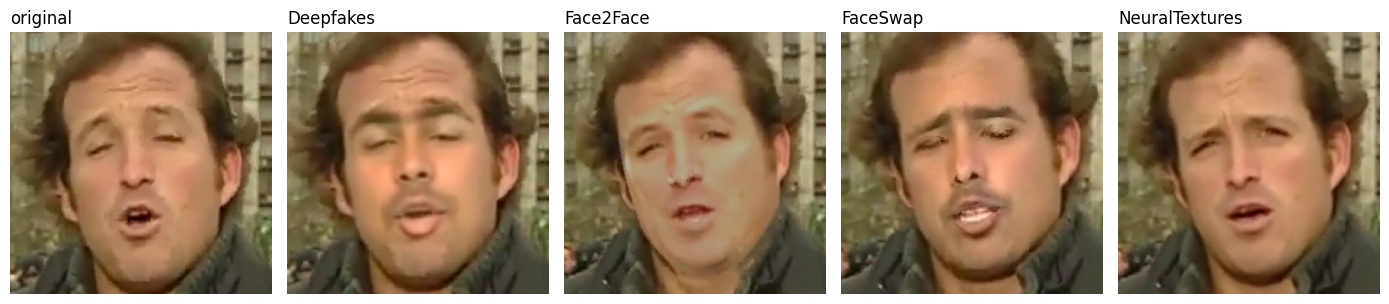

In [6]:
# Inspección visual: real vs. cada manipulación del mismo target
import matplotlib.pyplot as plt
from PIL import Image
a, b = te[0]
paths = [CROPS / D.REAL / a] + [CROPS / m / f"{a}_{b}" for m in D.METHODS]
fig, axes = plt.subplots(1, 5, figsize=(14, 3))
for ax, p in zip(axes, paths):
    fs = sorted(p.glob("*.png"))
    if fs: ax.imshow(Image.open(fs[len(fs) // 2]))
    ax.set_title(p.parent.name, loc="left"); ax.axis("off")
plt.tight_layout(); plt.savefig(ROOT / "results" / "ejemplo_recortes.png", dpi=150); plt.show()

In [7]:
# Liberar espacio: los videos ya no se necesitan
# !rm -rf {FFPP}
#!du -sh {CROPS}

In [8]:
import json, pandas as pd, numpy as np, torch, matplotlib.pyplot as plt
from train import Config, run
import plotstyle as S; S.apply()
# Dataset de Kaggle creado a partir del output del notebook 02 (o /kaggle/working/crops si se corre en la misma sesión)
CROPS = next(p for p in [Path(os.environ.get("CROPS_DIR", "/nonexistent")), Path("/kaggle/input/ffpp-crops-g8/crops"),
                         Path("/kaggle/working/crops")] if p.exists())
BASE = dict(crops_dir=str(CROPS), n_train_pairs=100, n_val_pairs=30, n_test_pairs=None,
            frames_per_video=16, epochs=6, warmup_epochs=1, batch_size=32, lr=2e-4, seed=42)
if os.environ.get("SMOKE"):  # prueba rápida del pipeline en CPU con datos sintéticos
    BASE.update(n_train_pairs=4, n_val_pairs=2, n_test_pairs=2, frames_per_video=3, epochs=2, batch_size=8, img_size=96, num_workers=0)
print(CROPS, torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

/kaggle/working/crops Tesla T4


## 1. Línea base: BCE (γ = 0)

In [9]:
res_bce = run(Config(run_name="bce_s42", gamma=0.0, **BASE))

{
 "train": {
  "frames": 6397,
  "frames_real": 3200,
  "frames_fake": 3197,
  "videos": 400,
  "videos_faltantes": 0
 },
 "val": {
  "frames": 1917,
  "frames_real": 960,
  "frames_fake": 957,
  "videos": 120,
  "videos_faltantes": 0
 }
}
Downloading: "https://github.com/rwightman/pytorch-image-models/releases/download/v0.1-cadene/xception-43020ad28.pth" to /root/.cache/torch/hub/checkpoints/xception-43020ad28.pth
[bce_s42] ep 1 (cabeza) loss=0.6638 fáciles=0.0% val_auc_frame=0.8136 val_auc_video=0.8619 (38s)
[bce_s42] ep 2 (red completa) loss=0.1028 fáciles=84.2% val_auc_frame=0.9977 val_auc_video=1.0000 (99s)
[bce_s42] ep 3 (red completa) loss=0.0209 fáciles=97.4% val_auc_frame=0.9986 val_auc_video=1.0000 (84s)
[bce_s42] ep 4 (red completa) loss=0.0235 fáciles=97.4% val_auc_frame=0.9982 val_auc_video=1.0000 (84s)
[bce_s42] ep 5 (red completa) loss=0.0092 fáciles=99.0% val_auc_frame=0.9982 val_auc_video=1.0000 (84s)
[bce_s42] ep 6 (red completa) loss=0.0117 fáciles=98.7% val_auc_fra

## 2. Intervención: Focal Loss (γ = 2)

In [10]:
res_fl = run(Config(run_name="focal_g2_s42", gamma=2.0, **BASE))

{
 "train": {
  "frames": 6397,
  "frames_real": 3200,
  "frames_fake": 3197,
  "videos": 400,
  "videos_faltantes": 0
 },
 "val": {
  "frames": 1917,
  "frames_real": 960,
  "frames_fake": 957,
  "videos": 120,
  "videos_faltantes": 0
 }
}
[focal_g2_s42] ep 1 (cabeza) loss=0.1600 fáciles=0.0% val_auc_frame=0.8326 val_auc_video=0.8808 (30s)
[focal_g2_s42] ep 2 (red completa) loss=0.0256 fáciles=56.9% val_auc_frame=0.9981 val_auc_video=1.0000 (84s)
[focal_g2_s42] ep 3 (red completa) loss=0.0068 fáciles=84.3% val_auc_frame=0.9960 val_auc_video=0.9994 (84s)
[focal_g2_s42] ep 4 (red completa) loss=0.0033 fáciles=91.7% val_auc_frame=0.9989 val_auc_video=1.0000 (83s)
[focal_g2_s42] ep 5 (red completa) loss=0.0031 fáciles=93.9% val_auc_frame=0.9961 val_auc_video=0.9997 (83s)
[focal_g2_s42] ep 6 (red completa) loss=0.0049 fáciles=90.0% val_auc_frame=0.9974 val_auc_video=1.0000 (84s)
  test Deepfakes       AUC frame=0.9968 video=0.9993
  test Face2Face       AUC frame=0.6751 video=0.6742
  test

## 3. Comparación

In [11]:
runs = {"BCE (γ=0)": res_bce, "Focal (γ=2)": res_fl}
rows = []
for name, r in runs.items():
    for m, t in r["test"].items():
        rows.append({"pérdida": name, "test": m, "AUC frame": t.get("auc_frame"), "AUC video": t.get("auc_video"),
                     "acc video": t.get("acc_video@0.5"), "videos": t.get("n_videos")})
tab = pd.DataFrame(rows)
indom = tab[tab.test == "Deepfakes"].set_index("pérdida")["AUC frame"]
tab["caída rel. vs in-domain (%)"] = tab.apply(lambda r: 100 * (indom[r["pérdida"]] - r["AUC frame"]) / indom[r["pérdida"]], axis=1)
tab.to_csv(ROOT / "results" / "comparacion_bce_vs_focal.csv", index=False)
pivot = tab.pivot(index="test", columns="pérdida", values="AUC frame")
pivot["Δ (focal − BCE)"] = pivot["Focal (γ=2)"] - pivot["BCE (γ=0)"]
pivot.round(4)

pérdida,BCE (γ=0),Focal (γ=2),Δ (focal − BCE)
test,,,
Deepfakes,0.9949,0.9968,0.0019
Face2Face,0.6986,0.6751,-0.0235
FaceSwap,0.3083,0.2845,-0.0238
NeuralTextures,0.8131,0.7967,-0.0164


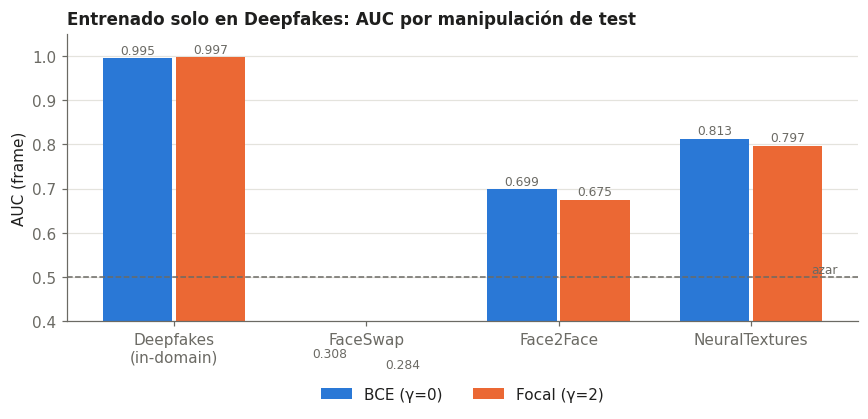

In [12]:
order = ["Deepfakes", "FaceSwap", "Face2Face", "NeuralTextures"]
x = np.arange(len(order)); w = 0.38
fig, ax = plt.subplots(figsize=(8, 4))
for i, (name, col) in enumerate(zip(runs, S.SERIES)):
    v = pivot.loc[order, name].values
    ax.bar(x + (i - 0.5) * w, v, w * 0.95, color=col, label=name)
    for xi, vi in zip(x, v): ax.text(xi + (i - 0.5) * w, vi + 0.01, f"{vi:.3f}", ha="center", fontsize=8, color=S.MUTED)
ax.axhline(0.5, color=S.MUTED, lw=1, ls="--"); ax.text(3.45, 0.51, "azar", color=S.MUTED, fontsize=8, ha="right")
ax.set_xticks(x, ["Deepfakes\n(in-domain)", "FaceSwap", "Face2Face", "NeuralTextures"])
ax.set_ylim(0.4, 1.05); ax.set_ylabel("AUC (frame)"); ax.grid(axis="x", visible=False)
ax.set_title("Entrenado solo en Deepfakes: AUC por manipulación de test", loc="left")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=2)
plt.tight_layout(); plt.savefig(ROOT / "results" / "fig_auc_cross_manipulation.png", dpi=200); plt.show()

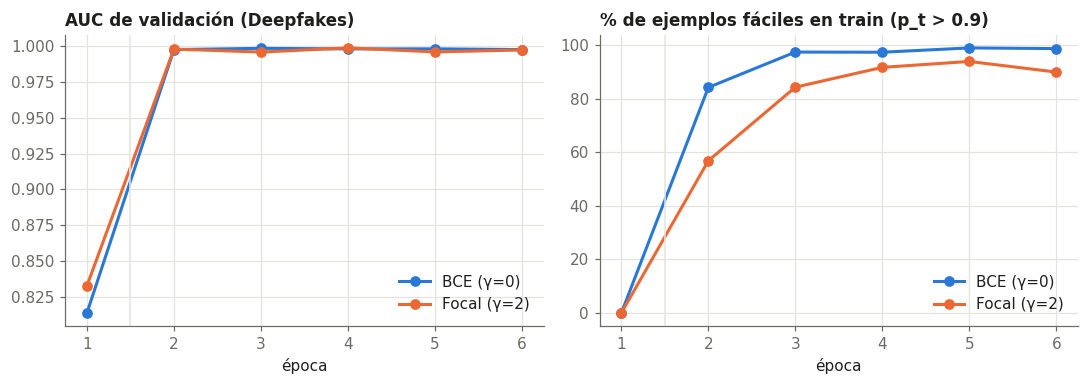

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for (name, r), col in zip(runs.items(), S.SERIES):
    h = pd.DataFrame(r["history"])
    axes[0].plot(h.epoch, h.val_auc_frame, marker="o", ms=6, color=col, label=name)
    axes[1].plot(h.epoch, h.train_pct_faciles, marker="o", ms=6, color=col, label=name)
axes[0].set_title("AUC de validación (Deepfakes)", loc="left"); axes[0].set_xlabel("época")
axes[1].set_title("% de ejemplos fáciles en train (p_t > 0.9)", loc="left"); axes[1].set_xlabel("época")
for a in axes: a.axvline(1.5, color=S.GRID, lw=1); a.legend()
plt.tight_layout(); plt.savefig(ROOT / "results" / "fig_curvas_entrenamiento.png", dpi=200); plt.show()

## 4. Grad-CAM: ¿dónde mira cada modelo?
> **Licencia:** esta celda muestra caras de FF++ (tag `caras`). Antes de subir el notebook ejecutado a GitHub, correr `python tools/limpiar_caras.py`; las figuras `fig_gradcam_*.png` están ignoradas por Git.

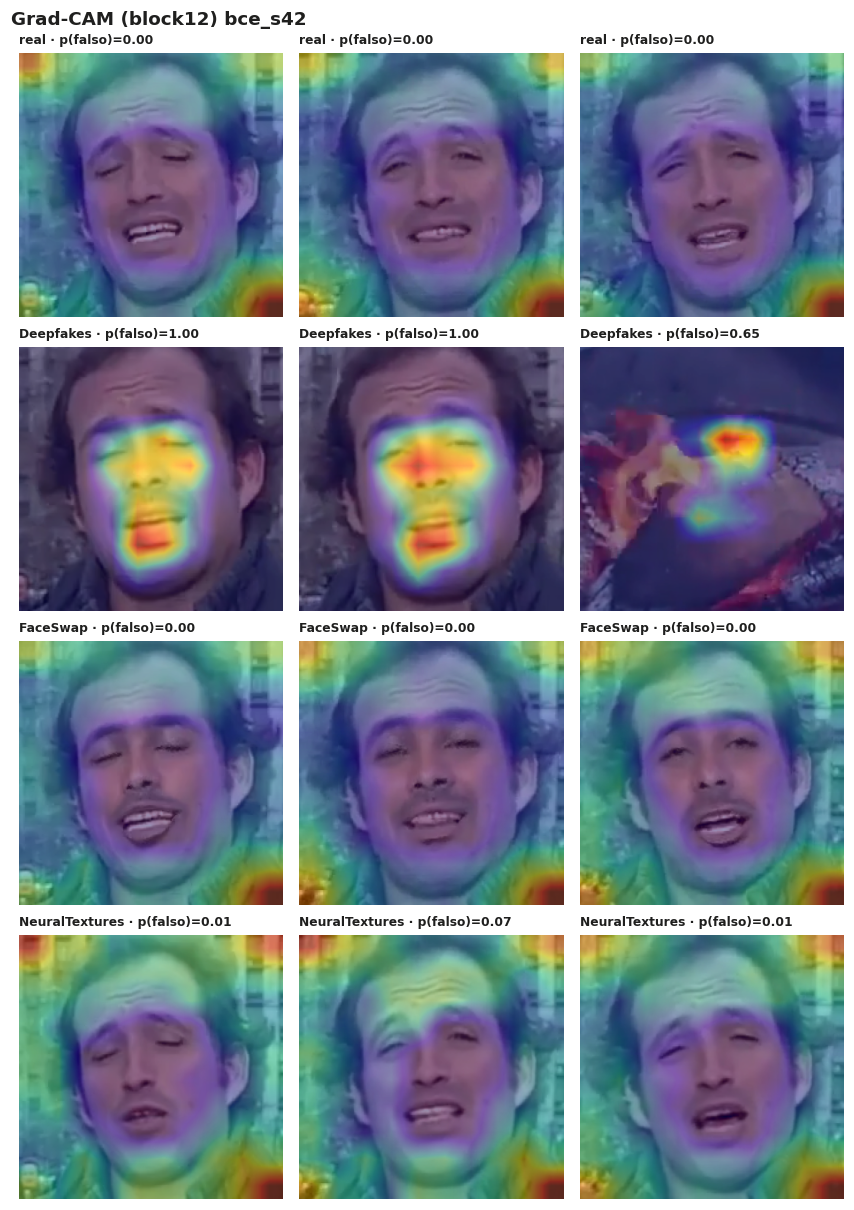

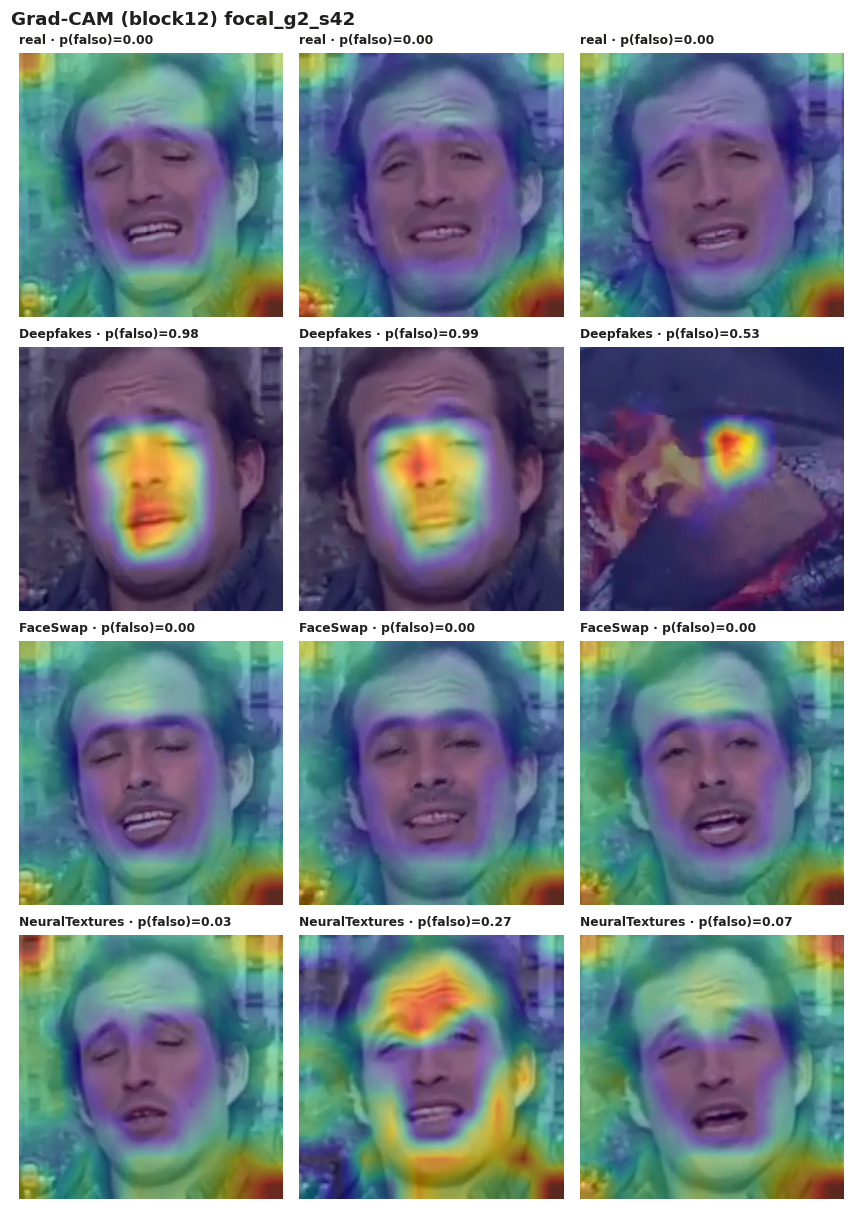

In [14]:
import glob, gradcam, data as D, teardown as T
from PIL import Image
tf = D.eval_transform(299)
te = D.load_pairs("results/splits", "test")
a, b = next(p for p in te if (CROPS / "FaceSwap" / f"{p[0]}_{p[1]}").exists()); pick = {}
for cat, vid in [("real", a), ("Deepfakes", f"{a}_{b}"), ("FaceSwap", f"{a}_{b}"), ("NeuralTextures", f"{a}_{b}")]:
    folder = CROPS / (D.REAL if cat == "real" else cat) / vid
    fs = sorted(folder.glob("*.png"))[:3]
    if fs: pick[cat] = torch.stack([tf(Image.open(f).convert("RGB")) for f in fs])
for run_name in ["bce_s42", "focal_g2_s42"]:
    m = T.build_model(False, 1); m.load_state_dict(torch.load(ROOT / "results" / "checkpoints" / f"{run_name}.pt", map_location="cpu")["model"])
    fig = gradcam.grid(m, pick, title=run_name); fig.savefig(ROOT / "results" / f"fig_gradcam_{run_name}.png", dpi=150); plt.show()

## 5. Contraste con la hipótesis *(completar después de correr)*
| Predicción | Resultado observado | ¿Se cumplió? | Explicación |
|---|---|---|---|
| 1. AUC in-domain casi igual | | | |
| 2. Mejora cross-manip., más en FaceSwap que en NeuralTextures | | | |
| 3. % de fáciles crece más lento con γ = 2 | | | |

**Advertencia de validez:** es una sola semilla y un subconjunto (100 pares de entrenamiento). Una diferencia de AUC menor a ~0.01–0.02 no debe interpretarse como efecto sin repetir con más semillas (planificado en el barrido de γ, Fase B completa).

| **Predicción** | **Resultado observado** | **¿Se cumplió?** | **Explicación** |
|---|---|---|---|
| AUC in-domain casi igual | En Deepfakes, el AUC por video fue 0.9981 con BCE y 0.9993 con Focal (Δ = +0.0012). | Sí, con una diferencia pequeña. | Ambos métodos obtuvieron AUC alto en la manipulación presente en entrenamiento. |
| Mejora cross-manipulation, especialmente en FaceSwap | El AUC por video con Focal fue menor en Face2Face (0.6742 vs. 0.6857), FaceSwap (0.2275 vs. 0.2459) y NeuralTextures (0.8204 vs. 0.8261). | No. | Focal no mejoró la generalización a las manipulaciones no vistas; el AUC disminuyó en las tres. |
| El porcentaje de ejemplos fáciles crece más lento con γ = 2 | En la época 6, los ejemplos fáciles fueron 90.0 % con Focal y 98.7 % con BCE. | Sí, según el registro de entrenamiento. | Con Focal, la proporción creció más lentamente y se mantuvo por debajo de BCE durante las épocas posteriores al calentamiento. |